# Taller: de modelo de lenguaje a asistente mediante ajuste supervisado
**SI3014 · Redes Neuronales y Aprendizaje Profundo · Universidad EAFIT**

En este taller ajustarás un modelo de lenguaje base con ejemplos de instrucciones y respuestas en español. Usarás **LoRA**, `peft` y `SFTTrainer` de TRL; no tendrás que implementar el entrenamiento desde cero.

**Objetivos:** preparar ejemplos para SFT, configurar un adaptador LoRA, entrenar y comparar el modelo antes y después.

**Trabajo:** ejecuta las celdas en orden, completa los **7 TODO** y responde las preguntas en las celdas de texto. Conserva las salidas como evidencia. Algunas celdas se detendrán hasta completar el TODO anterior.

**Entorno:** activa una GPU (por ejemplo, T4 en Colab o Kaggle) y conexión a internet. Se descargan el modelo Qwen2.5-0.5B y los datos Dolly en español. Los tiempos dependen del entorno. Sin GPU, el notebook corre con muy pocos ejemplos: sirve para recorrer el flujo, pero el ajuste es solo demostrativo.

**Antes de empezar:** ejecuta el Paso 0. Si instala paquetes, reinicia la sesión una vez y continúa desde el Paso 1.

**Entrega:** este notebook con los TODO completados, las salidas visibles y las respuestas breves. La calidad del modelo no se evalúa solo por una respuesta individual.

## Paso 0. Instalar dependencias
Ejecuta esta celda una vez. Si te pide reiniciar, hazlo (Colab: *Entorno de ejecución → Reiniciar sesión*; Kaggle: *Run → Restart & clear cell outputs*) y continúa con el Paso 1 sin volver a ejecutar esta celda.

In [1]:
import subprocess, sys
from importlib.metadata import version, PackageNotFoundError

VERSIONES = {'trl': '1.16.0', 'peft': '0.21.2'}   # fijadas para que todos trabajen con lo mismo

def instalada(paquete):
    try:
        return version(paquete)
    except PackageNotFoundError:
        return None

def pip(*args):
    subprocess.run([sys.executable, '-m', 'pip', *args, '-q'], check=True)

cambios = []
# Kaggle trae torchao 0.10, que las versiones recientes de transformers y peft rechazan al importarse
# ("Found an incompatible version of torchao"). Este notebook no lo usa: si es viejo, se desinstala.
v = instalada('torchao')
try:
    viejo = v is not None and tuple(int(x) for x in v.split('.')[:2]) < (0, 16)
except ValueError:
    viejo = False
if viejo:
    pip('uninstall', '-y', 'torchao')
    cambios.append('torchao desinstalado')

faltan = [f'{p}=={ver}' for p, ver in VERSIONES.items() if instalada(p) != ver]
if faltan:
    pip('install', *faltan)
    cambios.append('instalado: ' + ', '.join(faltan))

if cambios:
    print('Cambios:', '; '.join(cambios))
    print('→ Reinicia la sesión y continúa con el Paso 1.')
else:
    print('Todo listo: continúa con el Paso 1.')

Todo listo: continúa con el Paso 1.


## Paso 1. Preparar el entorno
Ejecuta la celda y verifica que el dispositivo sea `cuda`. No necesitas modificarla. Si falla al importar `trl` o `peft`, vuelve al Paso 0.

In [2]:
%pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')     # Kaggle "GPU T4 x2": una sola GPU, para que Trainer no use DataParallel

import math, random, textwrap, time
from collections import Counter
import matplotlib.pyplot as plt
import torch

import trl, peft, transformers, datasets               # si falla, ejecuta el Paso 0 y reinicia la sesión
from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import load_dataset
from peft import LoraConfig
from trl import SFTConfig, SFTTrainer

random.seed(0); torch.manual_seed(0)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('transformers', transformers.__version__, '· trl', trl.__version__, '· peft', peft.__version__, '·', dev)
if dev == 'cpu':
    print('Sin GPU: el notebook corre con muy pocos ejemplos. En Kaggle: Settings → Accelerator → GPU T4.')

transformers 5.8.1 · trl 1.16.0 · peft 0.21.2 · cuda


## Paso 2. Cargar el modelo base
El modelo base predice el siguiente token. Aún no ha sido ajustado específicamente para responder instrucciones. Ejecuta la carga y observa la cantidad de parámetros.

In [4]:
MODELO = 'Qwen/Qwen2.5-0.5B'          # el modelo BASE: solo preentrenado (token siguiente), sin SFT
tok = AutoTokenizer.from_pretrained(MODELO)
modelo = AutoModelForCausalLM.from_pretrained(MODELO, dtype=torch.float32).to(dev)
cfg = modelo.config
N_TOTAL = modelo.num_parameters()
print(f'{MODELO}: {N_TOTAL / 1e6:.0f} M parámetros · {cfg.num_hidden_layers} bloques · '
      f'd = {cfg.hidden_size} · {cfg.num_attention_heads} cabezas · |V| = {len(tok):,} · fin: {tok.eos_token!r}')

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Qwen/Qwen2.5-0.5B: 494 M parámetros · 24 bloques · d = 896 · 14 cabezas · |V| = 151,665 · fin: '<|endoftext|>'


### TODO 1 · Explorar el tokenizador
Escribe una frase en español y otra en inglés de significado similar. La celda cuenta sus tokens. Antes de ejecutarla, predice cuál necesitará más. Después explica lo observado; dos frases no permiten generalizar a todos los textos.

In [5]:
# TODO 1: pares de frases con el mismo significado (español, inglés).
# Hipótesis previa: en general el español usará más tokens, porque el tokenizador BPE parte más las
# palabras largas, derivadas o conjugadas del español. Pero el inglés puede necesitar más tokens cuando
# usa contracciones (don't, I'm) o auxiliares y sujetos explícitos que el español omite.
PARES = [
    # Gana el español (menos tokens): contracciones y sujetos explícitos en inglés
    ('No lo sé.',                 "I don't know."),
    ('Ya voy.',                   "I'm on my way."),
    # Empate
    ('Lo siento mucho.',          "I'm really sorry."),
    ('Voy a ir a la tienda.',     'I am going to go to the store.'),
    # Gana el inglés (menos tokens): palabras largas, derivadas y conjugadas en español
    ('Los estudiantes universitarios estaban preocupados por las evaluaciones.',
     'College students were worried about the exams.'),
    ('La inteligencia artificial está transformando la investigación científica.',
     'Artificial intelligence is transforming scientific research.'),
]

# El primer par se asigna a las variables originales para mantener las verificaciones de la plantilla
frase_es, frase_en = PARES[0]
assert isinstance(frase_es, str) and frase_es.strip(), "Escribe la frase en español"
assert isinstance(frase_en, str) and frase_en.strip(), "Escribe la frase en inglés"

def tokenizar(frase):
    ids = tok.encode(frase, add_special_tokens=False)
    return ids, [tok.decode([i]) for i in ids]

resumen = []
for k, (es, en) in enumerate(PARES, start=1):
    print(f'=== Par {k} ' + '=' * 70)
    n, palabras = {}, {}
    for idioma, frase in [('ES', es), ('EN', en)]:
        ids, piezas = tokenizar(frase)
        n[idioma], palabras[idioma] = len(ids), len(frase.split())
        print(f'{idioma} · {len(ids):2d} tokens · {palabras[idioma]:2d} palabras: {frase}')
        print('     ' + ' | '.join(piezas))
    gana = 'ES' if n['ES'] < n['EN'] else 'EN' if n['EN'] < n['ES'] else 'empate'
    resumen.append((k, n['ES'], n['EN'], palabras['ES'], palabras['EN'], gana))
    print(f'→ menos tokens: {gana} (ES/EN = {n["ES"] / n["EN"]:.2f})\n')

print('Resumen')
print(f'{"par":>3} | {"ES":>3} | {"EN":>3} | menos tokens')
for k, es_n, en_n, _, _, gana in resumen:
    print(f'{k:>3} | {es_n:>3} | {en_n:>3} | {gana}')
tok_es, tok_en = sum(r[1] for r in resumen), sum(r[2] for r in resumen)
pal_es, pal_en = sum(r[3] for r in resumen), sum(r[4] for r in resumen)
print(f'Total tokens: ES = {tok_es} · EN = {tok_en} · ES/EN = {tok_es / tok_en:.2f}')
print(f'Tokens por palabra: ES = {tok_es / pal_es:.2f} · EN = {tok_en / pal_en:.2f}')

=== Par 1 ======================================================================
ES ·  4 tokens ·  3 palabras: No lo sé.
     No |  lo |  sé | .
EN ·  5 tokens ·  3 palabras: I don't know.
     I |  don | 't |  know | .
→ menos tokens: ES (ES/EN = 0.80)

=== Par 2 ======================================================================
ES ·  3 tokens ·  2 palabras: Ya voy.
     Ya |  voy | .
EN ·  6 tokens ·  4 palabras: I'm on my way.
     I | 'm |  on |  my |  way | .
→ menos tokens: ES (ES/EN = 0.50)

=== Par 3 ======================================================================
ES ·  5 tokens ·  3 palabras: Lo siento mucho.
     Lo |  s | iento |  mucho | .
EN ·  5 tokens ·  3 palabras: I'm really sorry.
     I | 'm |  really |  sorry | .
→ menos tokens: empate (ES/EN = 1.00)

=== Par 4 ======================================================================
ES ·  9 tokens ·  6 palabras: Voy a ir a la tienda.
     V | oy |  a |  ir |  a |  la |  ti | enda | .
EN ·  9 tokens ·  8 pala

**Respuesta 1:** ¿Qué esperabas y qué observaste?

---

**Hipótesis previa.** Esperábamos que, en general, el español necesitara más tokens que el inglés para expresar lo mismo. Lo atribuíamos a que el tokenizador BPE de Qwen fusiona las secuencias de caracteres más frecuentes de su corpus de entrenamiento, y en él el inglés es, presumiblemente, más frecuente que el español. También esperábamos excepciones cuando el inglés usa contracciones o auxiliares y sujetos explícitos que el español omite.

**Resultados.** Probamos varios pares de frases equivalentes y dejamos seis, elegidos a propósito para mostrar los tres casos posibles:

| Par | Español | Inglés | Tokens ES | Tokens EN | Menos tokens |
|---|---|---|---|---|---|
| 1 | No lo sé. | I don't know. | 4 | 5 | ES |
| 2 | Ya voy. | I'm on my way. | 3 | 6 | ES |
| 3 | Lo siento mucho. | I'm really sorry. | 5 | 5 | Empate |
| 4 | Voy a ir a la tienda. | I am going to go to the store. | 9 | 9 | Empate |
| 5 | Los estudiantes universitarios estaban preocupados por las evaluaciones. | College students were worried about the exams. | 14 | 8 | EN |
| 6 | La inteligencia artificial está transformando la investigación científica. | Artificial intelligence is transforming scientific research. | 12 | 8 | EN |

En total, el español usó 47 tokens y el inglés 41 (ES/EN = 1,15), es decir, 1,57 tokens por palabra en español frente a 1,32 en inglés.

**Análisis de casos.**
- **Las contracciones del inglés cuestan tokens.** *don't* se parte en `don | 't` e *I'm* en `I | 'm`. Además, el inglés exige sujeto explícito y, en negaciones, el auxiliar *do*. Por eso *"No lo sé"* (`No | lo | sé | .`, 4 tokens) gana a *"I don't know"* (5), y *"Ya voy"* (3) gana con amplitud a *"I'm on my way"* (6). Las frases cortas y coloquiales del español, formadas por palabras muy frecuentes que son un solo token cada una, pueden ser más compactas.
- **Las palabras largas, derivadas o conjugadas del español se fragmentan.** *universitarios* se parte en `univers | it | arios`, *evaluaciones* en `evalu | aciones` y *estaban* en `est | aban`. Sus equivalentes en inglés (*College*, *exams*, *were*) son un solo token cada uno. Lo mismo ocurre con *transformando* (`transform | ando`) frente a *transforming* (un token), e *inteligencia* (`intelig | encia`) frente a *intelligence* (un token).
- **Las particiones del inglés suelen coincidir con unidades con significado; las del español, no siempre.** En inglés el tokenizador separa por contracciones (`don | 't`) o conserva palabras completas (*transforming*, *intelligence*). En español aparecen cortes que no corresponden a ninguna unidad del idioma, como *siento* → `s | iento` o *tienda* → `ti | enda`, mientras que *sorry* y *store* son un solo token. Algunos cortes en español sí coinciden con la morfología (`transform | ando` separa raíz y gerundio; `preocup | ados`, raíz y participio), pero el tokenizador no conoce la gramática: solo une lo que vio con frecuencia. Cuando una forma del español es poco frecuente en su corpus, el corte resulta arbitrario.
- **La posición de la palabra importa.** *Voy* al inicio de la frase se parte en `V | oy`, pero en *"Ya voy"* aparece como un único token ` voy`. La misma palabra cambia de tokenización según vaya en mayúscula y sin espacio delante (inicio de frase) o en minúscula con espacio (dentro de la frase), porque esta última forma es mucho más frecuente en el corpus. El efecto no es exclusivo del español: *Artificial* al inicio también se parte en `Art | ificial`.

**Conclusión y límites.** Se observa un patrón: el español tiende a necesitar más tokens por palabra, y sus particiones son menos interpretables que las del inglés. Esto es consistente con un tokenizador entrenado con más inglés que español. Sin embargo, no se puede generalizar. Son seis pares, elegidos a propósito para mostrar casos de los tres tipos, y no una muestra representativa del idioma. Además, el resultado depende del registro: el español coloquial y corto puede ser más compacto que el inglés, y el formal y técnico, mucho menos. Para concluir algo general habría que medir los tokens por palabra en un corpus paralelo grande.

**Por qué importa para este taller.** Más tokens por respuesta en español implica secuencias más largas, más cómputo por ejemplo y más riesgo de que una respuesta larga supere el límite de `max_length = 384` tokens del entrenamiento. Además, la pérdida y la perplejidad se miden por token, así que su valor depende de cómo se tokeniza cada idioma.

## Paso 3. Preparar el formato de entrenamiento
Cada ejemplo tendrá dos campos: `prompt`, que contiene la instrucción y el inicio de la respuesta, y `completion`, que contiene la respuesta esperada. TRL usa estos campos durante el entrenamiento.

In [6]:
def prompt(pregunta):
    return f'Usuario: {pregunta.strip()}\nAsistente:'

print(prompt('¿Qué es un átomo?'))

Usuario: ¿Qué es un átomo?
Asistente:


### TODO 2 · Crear un ejemplo
Completa la función: usa `prompt` con el campo `instruction` y coloca el contenido de `response` en `completion`, precedido por un espacio. La prueba debe imprimir el diccionario con ambos campos.

In [7]:
def a_ejemplo(e):
    # TODO 2: el prompt se construye con la instrucción; la respuesta va en completion, precedida por un espacio
    return {'prompt': prompt(e['instruction']), 'completion': ' ' + e['response'].strip()}

prueba = a_ejemplo({'instruction': '¿Qué es un átomo?', 'response': 'Una unidad básica de la materia.'})
assert isinstance(prueba['prompt'], str) and isinstance(prueba['completion'], str), 'Completa ambos campos'
print(prueba)

{'prompt': 'Usuario: ¿Qué es un átomo?\nAsistente:', 'completion': ' Una unidad básica de la materia.'}


**Respuesta 2:** ¿Qué información recibe el modelo como entrada y qué parte debe aprender a generar?

---

El modelo recibe como entrada la secuencia completa: el `prompt` (la instrucción con el formato `Usuario: …\nAsistente:`) seguido de la `completion` (la respuesta esperada). Durante el entrenamiento, en cada posición de la respuesta el modelo ve el prompt y los tokens anteriores de la respuesta, y debe predecir el siguiente token. Es la misma tarea de predecir el siguiente token del preentrenamiento, pero ahora sobre pares instrucción–respuesta.

Lo que debe aprender a generar es solo la `completion`: los tokens de la respuesta y, al final, el token de fin. El prompt actúa como contexto que condiciona la predicción, pero no se le pide al modelo que lo reproduzca. Con `completion_only_loss=True`, la pérdida se calcula únicamente sobre los tokens de la respuesta, y los del prompt quedan excluidos (lo verificamos en el Paso 7).

Por ejemplo, con *"Usuario: ¿Qué es un átomo?\nAsistente:"* como entrada, el modelo debe aprender a continuar con *" Una unidad básica de la materia."* y detenerse. El espacio inicial de la completion hace que la primera palabra de la respuesta use la forma tokenizada más frecuente (con espacio delante), como observamos en el TODO 1.

## Paso 4. Observar el modelo antes del ajuste
Estas funciones generan respuestas y muestran si el modelo produjo el token de fin. Ejecuta la celda.

In [8]:
@torch.no_grad()
def responder(m, pregunta, max_nuevos=120):
    """Greedy (diapositiva 46). Devuelve el texto y si el modelo produjo el token de fin."""
    x = tok(prompt(pregunta), return_tensors='pt').to(dev)
    out = m.generate(**x, max_new_tokens=max_nuevos, do_sample=False, eos_token_id=tok.eos_token_id,
                     pad_token_id=tok.eos_token_id)
    nuevos = out[0, x['input_ids'].shape[1]:]
    return tok.decode(nuevos, skip_special_tokens=True).strip(), bool((nuevos == tok.eos_token_id).any())

def mostrar(q, r, paro, ancho=100):
    print('▶', q)
    print(textwrap.indent(textwrap.fill(r.replace('\n', ' ⏎ ')[:700], ancho), '   '))
    print('   se detuvo:', 'sí' if paro else 'NO, llegó al límite de tokens')
    print()

PREGUNTAS = ['¿Qué es un átomo?',
             'Dame tres ideas para ahorrar agua en casa.',
             '¿Cuál es la diferencia entre el clima y el tiempo atmosférico?',
             'Clasifica estos animales en mamíferos o aves: perro, águila, ballena, gorrión.',
             'Escribe un haiku sobre la lluvia.']

### TODO 3 · Probar el modelo base
Agrega una pregunta propia a la lista. Ejecuta la comparación inicial y observa si las respuestas son pertinentes y si terminan.

**Hipótesis antes de ejecutar.** El modelo base solo fue entrenado para predecir el siguiente token, no para seguir instrucciones. Por eso esperamos que, ante las preguntas en formato `Usuario: …\nAsistente:`:
- responda de forma poco pertinente o incompleta, aunque con español fluido;
- continúe el texto en lugar de cerrar su respuesta: que invente nuevos turnos `Usuario:` / `Asistente:` o repita frases, lo que favorece la decodificación greedy;
- no se detenga y llegue al límite de 120 tokens nuevos, porque no aprendió a emitir el token de fin `<|endoftext|>` al terminar una respuesta.

Elegimos como pregunta propia una pregunta abierta de conocimiento general, *"¿Qué es una red neuronal artificial y para qué se utiliza?"*, porque es el tipo de instrucción más frecuente en Dolly. Así podremos comprobar en la Respuesta 7 si las preguntas parecidas a los datos de entrenamiento mejoran más.

In [9]:
# TODO 3: reemplaza None por una pregunta propia
pregunta_propia = '¿Qué es una red neuronal artificial y para qué se utiliza?'
assert isinstance(pregunta_propia, str) and pregunta_propia.strip(), 'Escribe una pregunta'
PREGUNTAS.append(pregunta_propia)
antes = {}
for q in PREGUNTAS:
    antes[q] = responder(modelo, q)
    mostrar(q, *antes[q])

▶ ¿Qué es un átomo?
   Un átomo es un elemento que tiene un solo电子 y una sola protona. Un átomo es un elemento que tiene un
   solo电子 y una sola protona. Un átomo es un elemento que tiene un solo electron y una sola protona. Un
   átomo es un elemento que tiene un solo electron y una sola protona. Un átomo es un elemento que
   tiene un solo electron y una sola protona. Un átomo es un elemento que tiene un solo electron y una
   sola protona. Un átomo es un elemento que tiene un solo electron
   se detuvo: NO, llegó al límite de tokens

▶ Dame tres ideas para ahorrar agua en casa.
   ¡Claro! Aquí tienes algunas ideas para ahorrar agua en casa: ⏎  ⏎ 1. **Utiliza el agua caliente**:
   Si tienes una cama o un baño, utiliza el agua caliente para lavar tu ropa. Esto reduce el consumo de
   agua y evita que la cama se quede caliente durante mucho tiempo. ⏎  ⏎ 2. **Utiliza el agua de la
   ducha**: Si tienes una ducha, utiliza la ducha para lavar tu ropa. Esto reduce el consumo de agua y
   

**Respuesta 3:** Describe una respuesta y si el modelo se detuvo. ¿Qué limitación observas?

---

La hipótesis se cumplió. **Solo 1 de las 6 respuestas se detuvo** (el haiku); las otras 5 llegaron al límite de 120 tokens. El modelo produce español mayormente fluido, pero no se comporta como un asistente.

- **"¿Cuál es la diferencia entre el clima y el tiempo atmosférico?"** La primera frase tiene forma de respuesta, aunque es incorrecta: el clima es el comportamiento promedio de la atmósfera durante largos periodos, y el tiempo atmosférico, su estado en un momento concreto. Inmediatamente después, el modelo **inventa nuevos turnos**: escribe `Asistente:`, repite la pregunta y repite su respuesta en bucle. No sabe dónde termina su turno y continúa el patrón de diálogo del prompt.
- **"¿Qué es un átomo?"** Repite la misma frase seis veces y además es incorrecta: *"tiene un solo electrón y una sola protona"* describe, en el mejor caso, al hidrógeno, y *"protona"* no existe. Aparece incluso el token chino **电子** (*electrón*) antes de cambiar a *electron*. Esta mezcla de idiomas es plausible en un modelo cuyo corpus de preentrenamiento incluye mucho texto en chino.
- **"Clasifica estos animales…"** Ignora la instrucción: no clasifica nada, repite la lista y describe al perro en un bucle.
- **Pregunta propia ("¿Qué es una red neuronal artificial…?")** Las dos primeras frases son razonables, pero luego repite casi literalmente la misma idea hasta agotar los tokens.
- **El único caso que se detuvo, el haiku**, empieza con *"¡Claro! Aquí tienes…"* y termina con *"¿Hay algo más que necesites?"*, con un estilo de asistente que sugiere que el corpus de preentrenamiento ya contenía texto de ese tipo. Aun así, el resultado no es un haiku: tiene cuatro versos y no sigue la métrica 5-7-5.

**Limitación observada.** El modelo base conoce el idioma, pero no ha aprendido la tarea de responder instrucciones: no se ajusta a lo que se pide (clasificar, dar tres ideas concretas), comete errores factuales y, sobre todo, **no sabe cuándo terminar su respuesta**, porque casi nunca emite `<|endoftext|>`. Parte de las repeticiones también se debe a la decodificación greedy, que tiende a caer en bucles al elegir siempre el token más probable. Por eso, la comparación del Paso 9 usa los mismos parámetros de generación antes y después del ajuste.

## Paso 5. Cargar y dividir los datos
Se usarán ejemplos Dolly traducidos automáticamente al español. Filtramos instrucciones que no requieren contexto adicional y respuestas de longitud moderada. La validación queda separada del entrenamiento.

In [10]:
DOLLY = 'argilla/databricks-dolly-15k-curated-multilingual'
crudo = load_dataset(DOLLY, split='es')
print('Ejemplos originales:', len(crudo))
print('Categorías:', Counter(crudo['category']).most_common())

def util(e):
    return (not (e['context'] or '').strip() and 20 <= len(e['response']) <= 700
            and len(e['instruction']) <= 300)

filtrado = crudo.filter(util).shuffle(seed=0)
print('Ejemplos después del filtro:', len(filtrado))

Ejemplos originales: 15015
Categorías: [('open_qa', 3611), ('general_qa', 2191), ('classification', 2136), ('closed_qa', 1823), ('brainstorming', 1768), ('information_extraction', 1512), ('summarization', 1263), ('creative_writing', 711)]
Ejemplos después del filtro: 7967


### TODO 4 · Seleccionar los datos y calcular los pasos
Las cantidades ya están fijadas: con GPU, 2 000 ejemplos de entrenamiento y 200 de validación; sin GPU, 48 y 16. Los ejemplos se seleccionan sin solapamiento y luego se transforman con tu función.

El entrenador procesará lotes de `BATCH` ejemplos durante una época. Completa `PASOS` con el número de actualizaciones de los parámetros que esperas en esa época, expresado con `N_TRAIN` y `BATCH`. Ten en cuenta que el último lote puede quedar incompleto. Lo compararás con el valor real en el Paso 8.

In [11]:
N_TRAIN, N_VAL = (2000, 200) if dev == 'cuda' else (48, 16)
BATCH = 8                                               # ejemplos por lote (se usa en el Paso 6)
assert N_TRAIN + N_VAL <= len(filtrado)
val_crudo = filtrado.select(range(N_VAL))
train_crudo = filtrado.select(range(N_VAL, N_VAL + N_TRAIN))
train = train_crudo.map(a_ejemplo, remove_columns=train_crudo.column_names)
val = val_crudo.map(a_ejemplo, remove_columns=val_crudo.column_names)
print('Entrenamiento:', len(train), '| Validación:', len(val))
print('Ejemplo:', train[0])

# TODO 4: un paso por lote; el último lote incompleto también cuenta, por eso se redondea hacia arriba
PASOS = math.ceil(N_TRAIN / BATCH)
assert isinstance(PASOS, int) and PASOS > 0, 'Escribe una expresión entera (pista: math)'
print('Pasos de optimización esperados en una época:', PASOS)

Entrenamiento: 2000 | Validación: 200
Ejemplo: {'prompt': 'Usuario: ¿Qué ventajas tiene bailar salsa?\nAsistente:', 'completion': ' Bailar salsa es una forma estupenda de conocer gente nueva. Ya sea mediante clases de baile o saliendo a un club de salsa, la naturaleza social del baile de salsa lo convierte en una buena forma de ampliar tu círculo social y aumentar tus actividades sociales.'}
Pasos de optimización esperados en una época: 250


**Respuesta 4:** ¿Por qué se reservan ejemplos de validación y no se usan para actualizar los parámetros?

---

La validación sirve para estimar cómo se comporta el modelo con ejemplos que **no vio durante el ajuste**, es decir, para medir si generaliza y no solo si memorizó los datos de entrenamiento. Si esos 200 ejemplos se usaran para actualizar los parámetros, la pérdida medida sobre ellos sería optimista: el modelo se habría ajustado precisamente a esos textos, y una pérdida baja ya no indicaría que funciona bien con instrucciones nuevas.

Mantenerlos separados permite además: (1) comparar de forma justa la pérdida **antes y después** del entrenamiento, sobre el mismo conjunto fijo; y (2) seguir la curva de validación durante el entrenamiento, para detectar sobreajuste (que la pérdida de entrenamiento siga bajando mientras la de validación se estanca o sube).

En el notebook, la separación es estricta: validación y entrenamiento salen de rangos disjuntos del dataset mezclado (`range(200)` y `range(200, 2200)`), y la validación solo se usa con `trainer.evaluate()`, nunca para calcular gradientes. Dos límites: son solo 200 ejemplos, así que la estimación tiene ruido; y como Dolly se tradujo automáticamente, ambos conjuntos comparten los mismos posibles errores de traducción, así que una pérdida baja no garantiza buen desempeño con texto escrito originalmente en español.

In [12]:
# Distribución de categorías en los 2 000 ejemplos de entrenamiento (para la Respuesta 7)
cats_train = Counter(train_crudo['category'])
for c, n in cats_train.most_common():
    print(f'{c:24s} {n:5d}  ({100 * n / len(train_crudo):.1f} %)')

open_qa                    690  (34.5 %)
classification             480  (24.0 %)
brainstorming              395  (19.8 %)
general_qa                 362  (18.1 %)
creative_writing            73  (3.6 %)


## Paso 6. Configurar LoRA y el entrenador
LoRA incorpora adaptadores entrenables de bajo rango, mientras mantiene congelados los pesos originales. TRL prepara los lotes y ejecuta el entrenamiento. Con `completion_only_loss=True`, la pérdida se calcula sobre la respuesta y no sobre el prompt.

### Configuración lista para ejecutar
La siguiente celda configura LoRA y el entrenador. **Ejecuta la celda sin modificarla**. LoRA permite ajustar un número reducido de parámetros y mantener congelados los pesos del modelo base. No necesitas conocer los detalles de su configuración para desarrollar el taller.

In [13]:
pasos_epoca = math.ceil(len(train) / BATCH)
# Con GPU (250 pasos) equivale a warmup 20, registro cada 10 y validación cada 50.
# En CPU (6 pasos) las frecuencias se reducen para que la curva tenga puntos.
lora = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.0,
                  task_type='CAUSAL_LM', target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj'])
args = SFTConfig(
    output_dir='sft_dolly', seed=0,
    completion_only_loss=True, max_length=384,
    num_train_epochs=1, per_device_train_batch_size=BATCH, per_device_eval_batch_size=BATCH,
    learning_rate=2e-4, lr_scheduler_type='cosine', warmup_steps=min(20, pasos_epoca // 10),
    max_grad_norm=1.0, weight_decay=0.0, fp16=dev == 'cuda', bf16=False,
    eval_strategy='steps', eval_steps=max(1, pasos_epoca // 5), logging_steps=max(1, pasos_epoca // 25),
    save_strategy='no', report_to='none')
trainer = SFTTrainer(model=modelo, args=args, train_dataset=train, eval_dataset=val,
                     processing_class=tok, peft_config=lora)
trainer.model.print_trainable_parameters()

trainable params: 2,162,688 || all params: 496,195,456 || trainable%: 0.4359


**Observación:** La celda muestra cuántos parámetros se entrenarán. No es necesario modificar ni explicar la configuración de LoRA.

## Paso 7. Inspeccionar la máscara de pérdida
Las etiquetas con valor `-100` se excluyen de la pérdida. Ejecuta la celda y compara la secuencia completa con los tokens que cuentan.

In [14]:
lote = next(iter(trainer.get_train_dataloader()))
ids, etiquetas = lote['input_ids'][0], lote['labels'][0]
reales = lote['attention_mask'][0].bool() if 'attention_mask' in lote else torch.ones_like(ids, dtype=torch.bool)
cuentan = ids[etiquetas != -100]
print('entra al modelo:     ', repr(tok.decode(ids[reales])))
print('cuenta en la pérdida:', repr(tok.decode(cuentan)))
print(f'{int((etiquetas != -100).sum())} de {int(reales.sum())} tokens tienen etiqueta; el resto vale -100 y no cuenta')
print('último token con etiqueta:', repr(tok.decode(cuentan[-1:])), '· token de fin del modelo:', repr(tok.eos_token))

entra al modelo:      'Usuario: ¿Cómo puedo ir de Singapur a San Francisco?\nAsistente: Hay varios vuelos directos de Singapur a San Francisco. Singapore Airlines y United Airlines ofrecen varios vuelos directos diarios que tardan unas 17h en cada sentido. Alternativamente, podrías tomar un vuelo de conexión en Japón que tardaría unas 20h. Conducir no funcionaría porque no hay una ruta terrestre continua de Singapur a San Francisco. Podrías tomar un barco, pero tendrías que encontrar uno que navegue por esta ruta, además de tardar 2 semanas en hacer el viaje.<|endoftext|>'
cuenta en la pérdida: ' Hay varios vuelos directos de Singapur a San Francisco. Singapore Airlines y United Airlines ofrecen varios vuelos directos diarios que tardan unas 17h en cada sentido. Alternativamente, podrías tomar un vuelo de conexión en Japón que tardaría unas 20h. Conducir no funcionaría porque no hay una ruta terrestre continua de Singapur a San Francisco. Podrías tomar un barco, pero tendrías que encon

**Respuesta 5:** ¿Por qué es razonable calcular la pérdida sobre la respuesta en este taller? ¿El prompt deja de ser una entrada para el modelo? Observa el último token con etiqueta: ¿qué aprende el modelo a predecir al final de cada respuesta y qué relación tiene con lo que viste en la Respuesta 3?

---

Es razonable calcular la pérdida solo sobre la respuesta porque el objetivo del ajuste es que el modelo aprenda a **responder**, no a escribir preguntas ni a reproducir la plantilla `Usuario: …\nAsistente:`. Si los tokens del prompt también contaran, parte del entrenamiento se dedicaría a predecir instrucciones de usuarios y la plantilla en sí. Eso refuerza justo el comportamiento que observamos en la Respuesta 3, cuando el modelo base inventaba nuevos turnos `Asistente:` y repetía la pregunta.

El prompt **no deja de ser entrada**: en el ejemplo inspeccionado, los 138 tokens entran al modelo y la atención usa el prompt completo como contexto para predecir cada token de la respuesta. Lo único que cambia es que sus 17 tokens tienen etiqueta `-100`, así que no generan error ni gradiente. Solo los 121 tokens de la respuesta (el 88 % de la secuencia en este ejemplo) cuentan en la pérdida.

El **último token con etiqueta es `<|endoftext|>`**, que coincide con el token de fin del modelo. Ese token no lo produjo el modelo: TRL lo añade al final de cada respuesta al preparar los datos. Así, en cada uno de los 2 000 ejemplos el modelo aprende que, después de completar la respuesta, lo que sigue es el fin de texto. Esto ataca directamente la limitación de la Respuesta 3, donde **5 de las 6** respuestas del modelo base no se detuvieron y llegaron al límite de 120 tokens: esperamos que, tras el ajuste, más respuestas terminen emitiendo `<|endoftext|>`.

## Paso 8. Evaluar y entrenar
Primero se mide la pérdida de validación del modelo base. Luego se entrena una época y se vuelve a medir. Una pérdida menor indica mejor predicción de las respuestas de validación según esta métrica, pero no garantiza respuestas correctas en todos los casos.

### TODO 5 · Medir antes del entrenamiento
Completa la llamada para evaluar el modelo y extraer `eval_loss`. Antes de ejecutar, anota una predicción: la perplejidad es el número efectivo de tokens entre los que el modelo «duda». ¿Esperas un valor cercano a |V| ≈ 151 000, cercano a 1 o intermedio? Lo retomarás en la Respuesta 6.

**Hipótesis antes de evaluar.** La pérdida que reporta `trainer.evaluate()` es la log-verosimilitud negativa promedio (NLL, en nats por token) de los tokens de la respuesta en las 200 instrucciones de validación:

$$
\text{NLL} = -\frac{1}{N}\sum_{t=1}^{N}\log p_\theta\!\left(x_t \mid x_{<t}\right), \qquad \text{PPL} = e^{\text{NLL}}
$$

La perplejidad puede interpretarse como el número efectivo de tokens entre los que el modelo "duda" en cada posición. Esperamos un valor **intermedio**, en el orden de unidades o pocas decenas:
- **Lejos de $|V| \approx 151\,000$:** ese valor correspondería a repartir la probabilidad uniformemente entre todo el vocabulario, y el modelo base ya domina el español, como se vio en sus respuestas fluidas del Paso 4.
- **Lejos de 1:** eso exigiría predecir cada token de la respuesta con certeza total, y el modelo base no conoce el estilo ni el contenido exacto de las respuestas de Dolly.

In [15]:
# TODO 5: evaluar el modelo antes del ajuste (LoRA con B = 0 equivale al modelo base)
evaluacion_antes = trainer.evaluate()
assert isinstance(evaluacion_antes, dict) and 'eval_loss' in evaluacion_antes, 'Evalúa con trainer.evaluate()'
J_antes = evaluacion_antes['eval_loss']
print(f'NLL antes: {J_antes:.3f} · perplejidad: {math.exp(J_antes):.1f}')

Training Loss,Validation Loss,Step,Entropy,Mean Token Accuracy,Num Tokens
No log,2.059911,0,2.029122,0.575575,0.000000


NLL antes: 2.060 · perplejidad: 7.8


### TODO 6 · Entrenar y evaluar
Completa las dos llamadas indicadas. El entrenamiento puede tardar varios minutos; no lo interrumpas si las métricas avanzan.

**Hipótesis antes de entrenar.** Esperamos que:
- la NLL de validación **disminuya** después de una época, porque el modelo aprende el formato, el estilo y la longitud de las respuestas de Dolly, y a cerrar cada respuesta con `<|endoftext|>`;
- la mayor parte de la mejora ocurra en los primeros pasos (adaptarse al formato es lo más "fácil" de aprender), con una curva que luego se aplana;
- el número de pasos del entrenador coincida con nuestro cálculo del TODO 4: $\lceil 2000/8 \rceil = 250$;
- con una sola época y solo un 0,44 % de parámetros entrenables, haya poco espacio para el sobreajuste: la pérdida de validación no debería subir de forma marcada.

In [16]:
t0 = time.time()
# TODO 6a: llama al método de entrenamiento de trainer
trainer.train()

SEGUNDOS = time.time() - t0
# TODO 6b: evalúa el modelo entrenado y guarda el diccionario
evaluacion_despues = trainer.evaluate()
assert trainer.state.global_step > 0, 'Ejecuta el entrenamiento'
assert isinstance(evaluacion_despues, dict) and 'eval_loss' in evaluacion_despues, 'Evalúa después de entrenar'
J_despues = evaluacion_despues['eval_loss']
assert math.isfinite(J_despues), ('La pérdida es nan o inf. Cambia fp16=True por fp16=False en el Paso 6 '
                                  'y vuelve a ejecutar desde el Paso 2.')
print(f'Tiempo: {SEGUNDOS/60:.1f} min | NLL: {J_antes:.3f} → {J_despues:.3f}')
print(f'Pasos: tu cálculo {PASOS} · entrenador {trainer.state.global_step}')

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
50,1.970497,1.925543,2.002604,0.599825,38018.000000
100,1.959669,1.916659,1.975422,0.600374,77412.000000
150,2.020562,1.908640,1.966257,0.604396,117932.000000
200,1.923262,1.904228,1.944185,0.604064,156394.000000
250,2.005465,1.903494,1.943412,0.604176,194881.000000


Training Loss,Validation Loss,Step,Entropy,Mean Token Accuracy,Num Tokens
2.005465,1.903494,250,1.943412,0.604176,194881.000000


Tiempo: 4.2 min | NLL: 2.060 → 1.903
Pasos: tu cálculo 250 · entrenador 250


Ejecuta la gráfica. La curva de validación tendrá pocos puntos si usas pocos ejemplos.

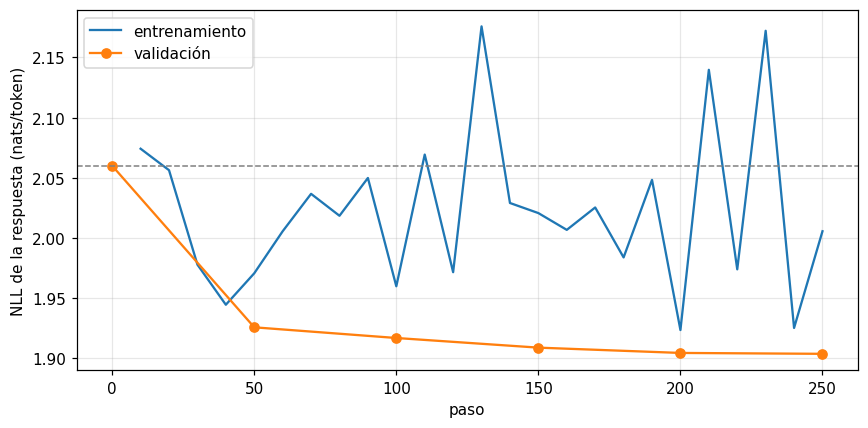

In [17]:
log = trainer.state.log_history
tr = [(r['step'], r['loss']) for r in log if 'loss' in r]
# trainer.evaluate() también queda en log_history; el diccionario evita repetir un mismo paso
ev = {0: J_antes}
ev.update({r['step']: r['eval_loss'] for r in log if 'eval_loss' in r})
ev = sorted(ev.items())
fig, ax = plt.subplots(figsize=(8, 4))
if tr:
    ax.plot(*zip(*tr), label='entrenamiento')
ax.plot(*zip(*ev), 'o-', label='validación')
ax.axhline(J_antes, color='gray', ls='--', lw=1)
ax.set_xlabel('paso'); ax.set_ylabel('NLL de la respuesta (nats/token)'); ax.legend()
plt.tight_layout(); plt.show()

**Respuesta 6:** Compara las pérdidas antes y después. ¿Qué sugiere el resultado? ¿Qué no puedes concluir solo a partir de esta métrica? ¿La perplejidad inicial se acercó a tu predicción? ¿Coincidió tu cálculo de `PASOS` con el del entrenador?

---

| Métrica (validación, 200 ejemplos) | Antes | Después | Cambio |
|---|---|---|---|
| NLL de la respuesta (nats/token) | 2,060 | 1,903 | −0,156 (−7,6 %) |
| Perplejidad ($e^{\text{NLL}}$) | 7,85 | 6,71 | −14,5 % |
| Exactitud media por token | 0,576 | 0,604 | +2,9 pp |
| Entropía media de la predicción | 2,029 | 1,943 | −0,086 |

**Qué sugiere el resultado.** Una sola época de ajuste con LoRA (250 pasos, 4,2 minutos, entrenando solo el 0,44 % de los parámetros) redujo la NLL de validación de 2,060 a 1,903. Sobre respuestas que no vio durante el entrenamiento, el modelo ajustado asigna mayor probabilidad a los tokens de la respuesta de referencia: pasa de "dudar" entre unos 7,8 tokens efectivos por posición a unos 6,7, y su predicción es algo más concentrada (menor entropía). La mejora se concentra al inicio: el **86 % de la reducción ocurrió en los primeros 50 pasos** (de 2,060 a 1,926), y entre los pasos 50 y 250 la pérdida de validación solo bajó 0,022. Esto es consistente con que lo primero que aprende el modelo es lo más regular de los datos (el formato, el estilo de Dolly y cerrar con `<|endoftext|>`), y después la ganancia es marginal. La pérdida de validación bajó de forma monótona en las cinco evaluaciones, así que no hay señales de sobreajuste en esta época.

La curva de entrenamiento oscila entre ≈1,92 y ≈2,18 porque cada punto promedia solo 10 lotes (80 ejemplos) distintos, con respuestas de dificultad muy variable. La de validación es suave porque siempre se mide sobre los mismos 200 ejemplos. Por eso, las subidas puntuales de la pérdida de entrenamiento no indican que el modelo empeore.

**Qué no se puede concluir solo con esta métrica.** Una NLL menor significa que el modelo predice mejor el texto de las respuestas de referencia, no que sus respuestas sean correctas, útiles o coherentes. La métrica se calcula con *teacher forcing*: el modelo siempre ve los tokens correctos anteriores, mientras que al generar se alimenta de sus propios tokens, que pueden ir acumulando errores. Además, las referencias son traducciones automáticas de Dolly, así que bajar la pérdida también puede significar imitar su estilo o sus errores de traducción. Tampoco sabemos qué parte de la mejora corresponde a contenido y qué parte a aprender el formato o el token de fin. Por último, hay una sola semilla, una sola época y 200 ejemplos de validación. Las mejoras reales deben comprobarse con la comparación de respuestas del Paso 9.

**Predicciones.** La perplejidad inicial (7,85) confirmó nuestra hipótesis: un valor intermedio, en el orden de unidades. Está muy lejos de |V| ≈ 151 000 porque el modelo base ya domina el español, y lejos de 1 porque, además de no conocer las respuestas de Dolly, una misma instrucción admite muchas respuestas válidas: incluso un modelo perfecto conservaría incertidumbre sobre qué palabras exactas usar, así que la perplejidad de un texto natural nunca llega a 1. El número de pasos también coincidió: calculamos ⌈2000/8⌉ = 250 y el entrenador ejecutó 250, porque 2 000 es múltiplo de 8 y no queda un lote incompleto.

**Reproducibilidad.** Al volver a ejecutar el notebook completo obtuvimos exactamente las mismas respuestas generadas, antes y después del ajuste, y una NLL de validación final que solo difiere en la cuarta cifra decimal (1,90356 frente a 1,90349), una variación numérica esperable al entrenar en precisión mixta (`fp16`) en GPU. Otro integrante del grupo ejecutó el mismo notebook en un equipo distinto (otra GPU y `transformers` 5.22.1 en lugar de 5.8.1; 20,8 min en lugar de 4,2) y obtuvo la misma NLL (2,060 → 1,903) y respuestas idénticas, palabra por palabra, en las preguntas compartidas. Con la misma semilla y decodificación greedy, el resultado es reproducible entre ejecuciones y entornos. Esto no mide la variabilidad entre semillas distintas, que sigue siendo una limitación del experimento.

## Paso 9. Comparar respuestas
Se utilizan las mismas preguntas y parámetros de generación del paso 4. Observa pertinencia, claridad y si el modelo se detiene.

### TODO 7 · Generar con el modelo ajustado
Completa la llamada a `responder` dentro del ciclo con el modelo ajustado `m` y la pregunta `q`.

**Hipótesis antes de comparar.** El ajuste enseñó al modelo a cerrar cada respuesta con `<|endoftext|>` y a seguir el formato instrucción → respuesta de Dolly. Por eso esperamos que el modelo ajustado:
- se detenga en **más de 1 de las 6** preguntas (el resultado del modelo base);
- deje de inventar turnos `Usuario:` / `Asistente:` y repita menos frases;
- mejore más en las preguntas parecidas a las categorías frecuentes del entrenamiento (preguntas abiertas de conocimiento, lluvia de ideas y clasificación).

También esperamos que los errores factuales persistan en parte: con 2 000 ejemplos y una sola época, el modelo aprende sobre todo **cómo** responder, pero apenas adquiere conocimiento nuevo. Y la decodificación greedy puede seguir produciendo repeticiones.

In [18]:
m = trainer.model
m.eval()
despues = {}
for q in PREGUNTAS:
    # TODO 7: genera y guarda la respuesta con el modelo ajustado
    despues[q] = responder(m, q)
    assert isinstance(despues[q], tuple), 'Usa responder(m, q)'
    print('ANTES  ', end=''); mostrar(q, *antes[q])
    print('DESPUÉS', end=''); mostrar(q, *despues[q])
    print('-' * 80)

# Resumen cuantitativo de la comparación (mismas preguntas y misma decodificación greedy)
paro_antes = sum(antes[q][1] for q in PREGUNTAS)
paro_despues = sum(despues[q][1] for q in PREGUNTAS)
print(f'Se detuvieron: antes {paro_antes}/{len(PREGUNTAS)} · después {paro_despues}/{len(PREGUNTAS)}')
print(f'{"pregunta":60s} | tokens antes | tokens después')
for q in PREGUNTAS:
    n_a = len(tok.encode(antes[q][0], add_special_tokens=False))
    n_d = len(tok.encode(despues[q][0], add_special_tokens=False))
    print(f'{q[:60]:60s} | {n_a:12d} | {n_d:14d}')

ANTES  ▶ ¿Qué es un átomo?
   Un átomo es un elemento que tiene un solo电子 y una sola protona. Un átomo es un elemento que tiene un
   solo电子 y una sola protona. Un átomo es un elemento que tiene un solo electron y una sola protona. Un
   átomo es un elemento que tiene un solo electron y una sola protona. Un átomo es un elemento que
   tiene un solo electron y una sola protona. Un átomo es un elemento que tiene un solo electron y una
   sola protona. Un átomo es un elemento que tiene un solo electron
   se detuvo: NO, llegó al límite de tokens

DESPUÉS▶ ¿Qué es un átomo?
   Un átomo es un elemento que tiene un número de protones y un número de electrones.
   se detuvo: sí

--------------------------------------------------------------------------------
ANTES  ▶ Dame tres ideas para ahorrar agua en casa.
   ¡Claro! Aquí tienes algunas ideas para ahorrar agua en casa: ⏎  ⏎ 1. **Utiliza el agua caliente**:
   Si tienes una cama o un baño, utiliza el agua caliente para lavar tu ropa. Esto r

**Respuesta 7:** Compara al menos dos preguntas, incluida la propia. Indica un cambio observado y una limitación que permanezca. ¿Cambió la capacidad de detenerse? Revisa las categorías de Dolly del Paso 5: ¿las preguntas que más mejoraron se parecen a las categorías más frecuentes en los datos?

---

La comparación usa las mismas seis preguntas y la misma decodificación greedy que el Paso 4; la única diferencia es el ajuste con LoRA.

| Pregunta | Categoría más cercana (% en train) | ¿Se detuvo? antes → después | Tokens antes → después |
|---|---|---|---|
| ¿Qué es un átomo? | `open_qa` (34,5 %) | No → Sí | 120 → 21 |
| Tres ideas para ahorrar agua | `brainstorming` (19,8 %) | No → Sí | 120 → 52 |
| Clima vs. tiempo atmosférico | `general_qa` (18,1 %) | No → No | 120 → 120 |
| Clasificar animales | `classification` (24,0 %) | No → Sí | 120 → 29 |
| Haiku sobre la lluvia | `creative_writing` (3,6 %) | Sí → Sí | 77 → 18 |
| Red neuronal artificial (propia) | `open_qa` (34,5 %) | No → No | 120 → 120 |

**Cambio observado: el modelo aprendió a detenerse y a seguir el formato pedido.** Las respuestas que terminaron con `<|endoftext|>` pasaron de **1 de 6 a 4 de 6**, y ninguna volvió a inventar turnos `Usuario:` / `Asistente:`. Es justo lo que esperábamos tras ver en el Paso 7 que el último token con etiqueta de cada ejemplo es el token de fin. Por ejemplo, en *"Clasifica estos animales…"* el modelo base repetía la lista y describía al perro en bucle; el ajustado responde con el formato `Perro: mamífero ⏎ Águila: aves ⏎ …` y se detiene en 29 tokens. En *"¿Qué es un átomo?"* pasó de repetir seis veces una frase errónea a una sola frase de 21 tokens.

**Limitación que permanece: el contenido sigue siendo poco confiable.** En la clasificación, el modelo ajustado se equivoca en **2 de los 4 animales** (la ballena no es un ave y el gorrión no es un mamífero): aprendió **cómo** se presenta una clasificación, pero no adquirió el conocimiento para hacerla bien. Las tres ideas para ahorrar agua tienen la forma de una lista numerada, pero son incoherentes ("agua de la cama") y la segunda y la tercera son idénticas. Con 2 000 ejemplos y una época, el ajuste cambia sobre todo el comportamiento, no los conocimientos del modelo.

**Pregunta propia ("¿Qué es una red neuronal artificial…?").** No mejoró de forma clara. Ya no inventa turnos, pero la respuesta empieza con una definición circular (*"es una red neuronal que se utiliza para…"*) y repite la misma frase hasta agotar los 120 tokens, igual que antes. Lo mismo ocurre con *"Clima vs. tiempo"*: desapareció el turno `Asistente:` inventado, pero la explicación sigue siendo incorrecta y se repite en bucle. En estos dos casos la repetición se debe en parte a la decodificación greedy, que tiende a caer en ciclos al elegir siempre el token más probable.

**Relación con las categorías de Dolly.** Tras el filtro, el entrenamiento quedó dominado por `open_qa` (34,5 %), `classification` (24,0 %), `brainstorming` (19,8 %) y `general_qa` (18,1 %); `creative_writing` representa solo el 3,6 %. Las mejoras más claras en formato y detención aparecieron en preguntas de las categorías frecuentes: clasificación, lluvia de ideas y la pregunta abierta sobre el átomo. El único caso que **empeoró** es el haiku, de la categoría menos representada: el modelo base producía un poema (aunque no fuera un haiku), y el ajustado responde con una sola frase en prosa (*"La lluvia es un gran regalo…"*). Es plausible que haya aprendido a dar respuestas breves y directas, como la mayoría de los ejemplos, a costa de la escritura creativa. Sin embargo, la relación no es perfecta: nuestra pregunta propia también es de `open_qa` y no se detuvo. Con seis preguntas, una sola semilla y decodificación greedy, esto es una observación cualitativa y no una conclusión general.

## Cierre

**1. Diferencia entre un modelo base y uno ajustado mediante SFT.**
Un **modelo base** se preentrena con un único objetivo: predecir el siguiente token sobre grandes cantidades de texto. Así aprende el idioma, mucha información del mundo y patrones de escritura, pero no aprende la tarea de **responder** a una instrucción. Ante una pregunta continúa el texto como lo haría un documento cualquiera. En nuestro caso, el modelo base Qwen2.5-0.5B escribía en un español fluido, pero inventaba turnos `Asistente:`, repetía frases y solo se detuvo en **1 de 6** preguntas.

El **ajuste supervisado (SFT)** sigue entrenando el mismo modelo con la misma pérdida de entropía cruzada, pero sobre pares instrucción → respuesta, calculando la pérdida solo sobre los tokens de la respuesta y terminando cada una con `<|endoftext|>`. Así el modelo aprende **el comportamiento de un asistente**: a qué parte del texto le corresponde responder, con qué formato y cuándo terminar. Con LoRA esto se hizo entrenando solo el 0,44 % de los parámetros (2.162.688) y sin modificar los pesos originales. Tras una época, el modelo se detuvo en **4 de 6** preguntas y respetó formatos como la lista numerada o la clasificación `animal: clase`. Sin embargo, sus errores de contenido se mantuvieron (por ejemplo, clasificó la ballena como ave): el SFT con pocos datos cambia sobre todo **cómo** responde el modelo, no **lo que sabe**.

**2. Por qué es útil comparar el modelo antes y después del ajuste.**
Porque es la única forma de **atribuir** los cambios al ajuste. Al mantener fijo todo lo demás (las mismas preguntas, la misma decodificación greedy, el mismo formato de prompt y el mismo conjunto de validación), cualquier diferencia se debe al entrenamiento con LoRA. Además, como LoRA empieza con $B = 0$, la evaluación "antes" mide exactamente el modelo base. Sin esa línea base no sabríamos si el modelo ajustado se detiene por lo que aprendió o porque el modelo base ya lo hacía.

La comparación también revela lo que **no** mejoró o incluso **empeoró**, algo que una sola métrica oculta. La NLL de validación bajó de 2,060 a 1,903, pero la comparación cualitativa mostró que dos respuestas siguieron repitiéndose hasta el límite, que la clasificación tiene el formato correcto pero la mitad de las respuestas son incorrectas, y que el haiku, de la categoría menos representada (3,6 %), empeoró. Comparar de las dos formas, cuantitativa y cualitativa, evita sobrevalorar el resultado del ajuste.

**3. Qué ejemplos o criterios adicionales usaríamos para evaluar mejor el asistente.**
- **Un conjunto de prueba más grande y balanceado por categoría:** decenas de instrucciones por categoría (incluida escritura creativa, que quedó subrepresentada), nunca vistas en el entrenamiento y, preferiblemente, escritas originalmente en español y no traducidas.
- **Métricas automáticas por criterio**, en lugar de una impresión general:
  - **exactitud**, en tareas con respuesta verificable (por ejemplo, el porcentaje de animales bien clasificados);
  - **cumplimiento de la instrucción** (¿dio exactamente tres ideas?, ¿el poema tiene la métrica de un haiku?);
  - **tasa de detención** (fracción de respuestas que terminan con `<|endoftext|>`);
  - **tasa de repetición** (proporción de n-gramas repetidos dentro de una respuesta);
  - **longitud** de las respuestas.
- **Evaluación humana con una rúbrica** de pertinencia, corrección, claridad y coherencia, idealmente comparando "antes" y "después" a ciegas, sin que el evaluador sepa qué modelo generó cada respuesta.
- **Comportamiento ante instrucciones problemáticas:** preguntas que el asistente debería rechazar o responder con cautela (peticiones dañinas, consultas médicas o legales, preguntas sin respuesta posible), para comprobar si el ajuste solo con datos de Dolly le enseña algún criterio de cuándo no responder.
- **Robustez del experimento:** varias semillas y más épocas, para saber si las diferencias son estables y no fruto del azar, y evaluar también con decodificación por muestreo (temperatura, penalización de repetición), separando el efecto del ajuste del efecto de la estrategia de generación.
- **Un punto de referencia externo**, como la versión *Instruct* oficial del mismo modelo (Qwen2.5-0.5B-Instruct), para dimensionar cuánto se acercó nuestro ajuste de 2 000 ejemplos a un asistente entrenado con muchos más datos.

### Referencias
- [Datos Dolly multilingües](https://huggingface.co/datasets/argilla/databricks-dolly-15k-curated-multilingual).
- [Documentación de TRL](https://huggingface.co/docs/trl) y [PEFT](https://huggingface.co/docs/peft).
- Hu et al. (2021), *LoRA: Low-Rank Adaptation of Large Language Models*; Ouyang et al. (2022), *Training language models to follow instructions with human feedback*.